# ActivityLink: activity recognition

We train a linear SVM to recognise six activities from the UCI HAR dataset, evaluate its predictions and export the model to C for the activity dongle.

The device uses stored feature vectors rather than live sensor readings. Its LED shows green for movement and blue for posture; moving the board does not change the input measurements.

## 1. Setup

This notebook contains dataset preparation, parameter selection, validation, final training, C export and evaluation.

Use a Python 3.11+ kernel. Dependencies and their versions are listed in `requirements-notebook.txt`.

- **Locally:** from the project root, run `python -m pip install -r requirements-notebook.txt` in the environment selected as the notebook kernel before executing the cells.
- **On Google Colab:** open the notebook and upload `requirements-notebook.txt` through the **Files** panel before running the next cell. Leave the file in the current working directory, normally `/content`. The cell installs dependencies from this file automatically. It is self-contained: you do not need to upload `requirements-ml.txt` or the project ZIP. If installation requires a runtime restart, restart and run the cells from the beginning; upload the file again if the runtime's files were reset.

A C compiler available as `gcc` is needed for the Python/C comparison.

The dataset is downloaded and its ZIP checksum verified unless `ACTIVITYLINK_DATASET` points to an existing extracted copy. Results are saved in a new directory under `results/` in the current working directory.


In [1]:
from pathlib import Path
from datetime import datetime
import ctypes
import hashlib
import json
import os
import shutil
import subprocess
import sys
import urllib.request
import zipfile

try:
    import google.colab
except ImportError:
    ON_COLAB = False
else:
    ON_COLAB = True

if ON_COLAB:
    requirements = Path("requirements-notebook.txt")
    if not requirements.is_file():
        raise FileNotFoundError(
            "Upload requirements-notebook.txt through the Colab Files panel "
            "into the current working directory before running this cell."
        )
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-r", str(requirements)], check=True,
    )

import numpy as np
import sklearn
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from sklearn.base import clone
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

stamp = datetime.now().strftime("%Y%m%d-%H%M%S-%f")
OUT = Path(os.environ.get("ACTIVITYLINK_RESULTS_DIR", Path.cwd() / "results" / f"notebook-{stamp}")).resolve()
OUT.mkdir(parents=True, exist_ok=False)
print("Results:", OUT)
print("NumPy:", np.__version__, "scikit-learn:", sklearn.__version__)

Results: /Users/martina/ActivityLink-IoT-2026/runtime/notebook-standalone-review/execution-results-exploration
NumPy: 2.3.5 scikit-learn: 1.8.0


## 2. Dataset

We use [Human Activity Recognition Using Smartphones](https://doi.org/10.24432/C54S4K), by Reyes-Ortiz et al., distributed under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Each row contains 561 features already extracted from smartphone accelerometer and gyroscope recordings, an activity label and a subject identifier. We use these features directly, without processing the raw signals.


The 561 features are numerical summaries of each 2.56-second recording window (128 samples at 50 Hz), not 561 different sensors:

- **Source signals:** the three accelerometer and gyroscope axes, body and gravity acceleration, signal magnitudes and rates of change.
- **Time-domain features:** summaries of how the readings change during a window, such as their average, variability, range, energy and correlations between axes.
- **Frequency-domain features:** summaries of the rhythm of movement: how quickly it repeats and how strong its slower or faster oscillations are. The Fast Fourier Transform (FFT) separates the recorded signal into rhythms of different frequencies. For example, 2 Hz means two cycles of a rise-and-fall pattern in the sensor reading per second.
- **Posture features:** angles relative to gravity provide information about orientation.
- **Why 561 columns:** different summaries are calculated for different signals and axes. For example, `tBodyAcc-mean()-X` is mean body acceleration along X, while `fBodyAcc-energy()-X` measures the overall strength of its frequency-domain representation.
- **Preprocessing:** the dataset supplies these extracted, normalised features. Our scaler subsequently learns its statistics only within the permitted training rows.

**Example: standing versus walking.**

- **Standing:** the phone's acceleration readings stay nearly constant, apart from small movements and noise.
- **Walking:** the readings rise and fall repeatedly as the person's body moves with each step.
- **What the FFT shows:** it helps identify this repeated pattern; walking usually produces a stronger movement rhythm than standing.
- **What 2 Hz means:** a rise-and-fall pattern in the sensor reading repeats roughly twice per second. This does not automatically mean exactly two steps per second.

<table>
  <thead>
    <tr>
      <th>Label</th>
      <th>Activity</th>
      <th>Device LED</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>1</td>
      <td>Walking</td>
      <td style="background-color: #065f46; color: #d1fae5; font-weight: bold;">Green</td>
    </tr>
    <tr>
      <td>2</td>
      <td>Walking upstairs</td>
      <td style="background-color: #065f46; color: #d1fae5; font-weight: bold;">Green</td>
    </tr>
    <tr>
      <td>3</td>
      <td>Walking downstairs</td>
      <td style="background-color: #065f46; color: #d1fae5; font-weight: bold;">Green</td>
    </tr>
    <tr>
      <td>4</td>
      <td>Sitting</td>
      <td style="background-color: #1e40af; color: #dbeafe; font-weight: bold;">Blue</td>
    </tr>
    <tr>
      <td>5</td>
      <td>Standing</td>
      <td style="background-color: #1e40af; color: #dbeafe; font-weight: bold;">Blue</td>
    </tr>
    <tr>
      <td>6</td>
      <td>Laying</td>
      <td style="background-color: #1e40af; color: #dbeafe; font-weight: bold;">Blue</td>
    </tr>
  </tbody>
</table>


The official split contains 7,352 training windows from 21 people and 2,947 test windows from nine other people. We load only the training files here. The test files are used after fitting the final model.

The hardware demonstration replays 24 stored feature vectors. These demonstrate prediction on the device and do not provide another accuracy estimate.

In [2]:
DATASET_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
# Verify the downloaded ZIP is intact and matches the expected dataset.
DATASET_SHA256 = "c00b803081a5c797cd5e4b83700a9810b38d53d9d84e01917e090e1fdbc81031"
def prepare_dataset(out):
    archive_path = out / "har.zip"
    with urllib.request.urlopen(DATASET_URL, timeout=120) as source, archive_path.open("wb") as target:
        shutil.copyfileobj(source, target)
    archive_sha256 = hashlib.sha256(archive_path.read_bytes()).hexdigest()
    if archive_sha256 != DATASET_SHA256:
        raise RuntimeError("Dataset checksum mismatch")
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(out / "download")
    with zipfile.ZipFile(out / "download" / "UCI HAR Dataset.zip") as archive:
        archive.extractall(out)
    print("Downloaded ZIP checksum verified")
    return out / "UCI HAR Dataset"

configured_dataset = os.environ.get("ACTIVITYLINK_DATASET")
if configured_dataset:
    DATASET = Path(configured_dataset).resolve()
else:
    DATASET = prepare_dataset(OUT)
if configured_dataset:
    print("Using an extracted local copy; the original ZIP checksum is not checked")
print("Dataset directory:", DATASET)
print("Download source:", DATASET_URL)
print("Expected archive SHA-256:", DATASET_SHA256)

# Only official training measurements are opened before candidate fitting
training_paths = [DATASET / "train" / name for name in
                  ["X_train.txt", "y_train.txt", "subject_train.txt"]]
X = np.loadtxt(training_paths[0])
y = np.loadtxt(training_paths[1], dtype=int)
subjects = np.loadtxt(training_paths[2], dtype=int)
assert X.shape == (7352, 561)
assert len(y) == len(subjects) == len(X)
assert len(np.unique(subjects)) == 21
assert np.isfinite(X).all()
assert set(y) == set(range(1, 7))
CLASSES = np.arange(1, 7)
ACTIVITIES = ["Walking", "Upstairs", "Downstairs", "Sitting", "Standing", "Laying"]
print("Training shape:", X.shape)
print("Training subjects:", len(np.unique(subjects)))
rows = ["| Activity | Training windows |", "|---|---:|"]
for label, name in zip(CLASSES, ACTIVITIES):
    rows.append(f"| {name} | {np.sum(y == label)} |")
display(Markdown("\n".join(rows)))

Using an extracted local copy; the original ZIP checksum is not checked
Dataset directory: /Users/martina/ActivityLink-IoT-2026/results/2026-11-02-final/ml-reproduction/UCI HAR Dataset
Download source: https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip
Expected archive SHA-256: c00b803081a5c797cd5e4b83700a9810b38d53d9d84e01917e090e1fdbc81031


Training shape: (7352, 561)
Training subjects: 21


| Activity | Training windows |
|---|---:|
| Walking | 1226 |
| Upstairs | 1073 |
| Downstairs | 986 |
| Sitting | 1286 |
| Standing | 1374 |
| Laying | 1407 |

### A first look at the training data

The plots below connect the feature table to the activities. Alongside the number of training windows, we explore four examples: variability in body acceleration (movement), variability in angular velocity measured by the gyroscope (rotation), mean gravity acceleration along the phone's X axis (orientation), and mean gravity acceleration along Y (an additional view of posture).

Each box covers the middle 50% of the activity's windows, with a line at the median; whiskers extend to the most extreme observations within 1.5 box widths of the box. Individual outliers are omitted for readability.

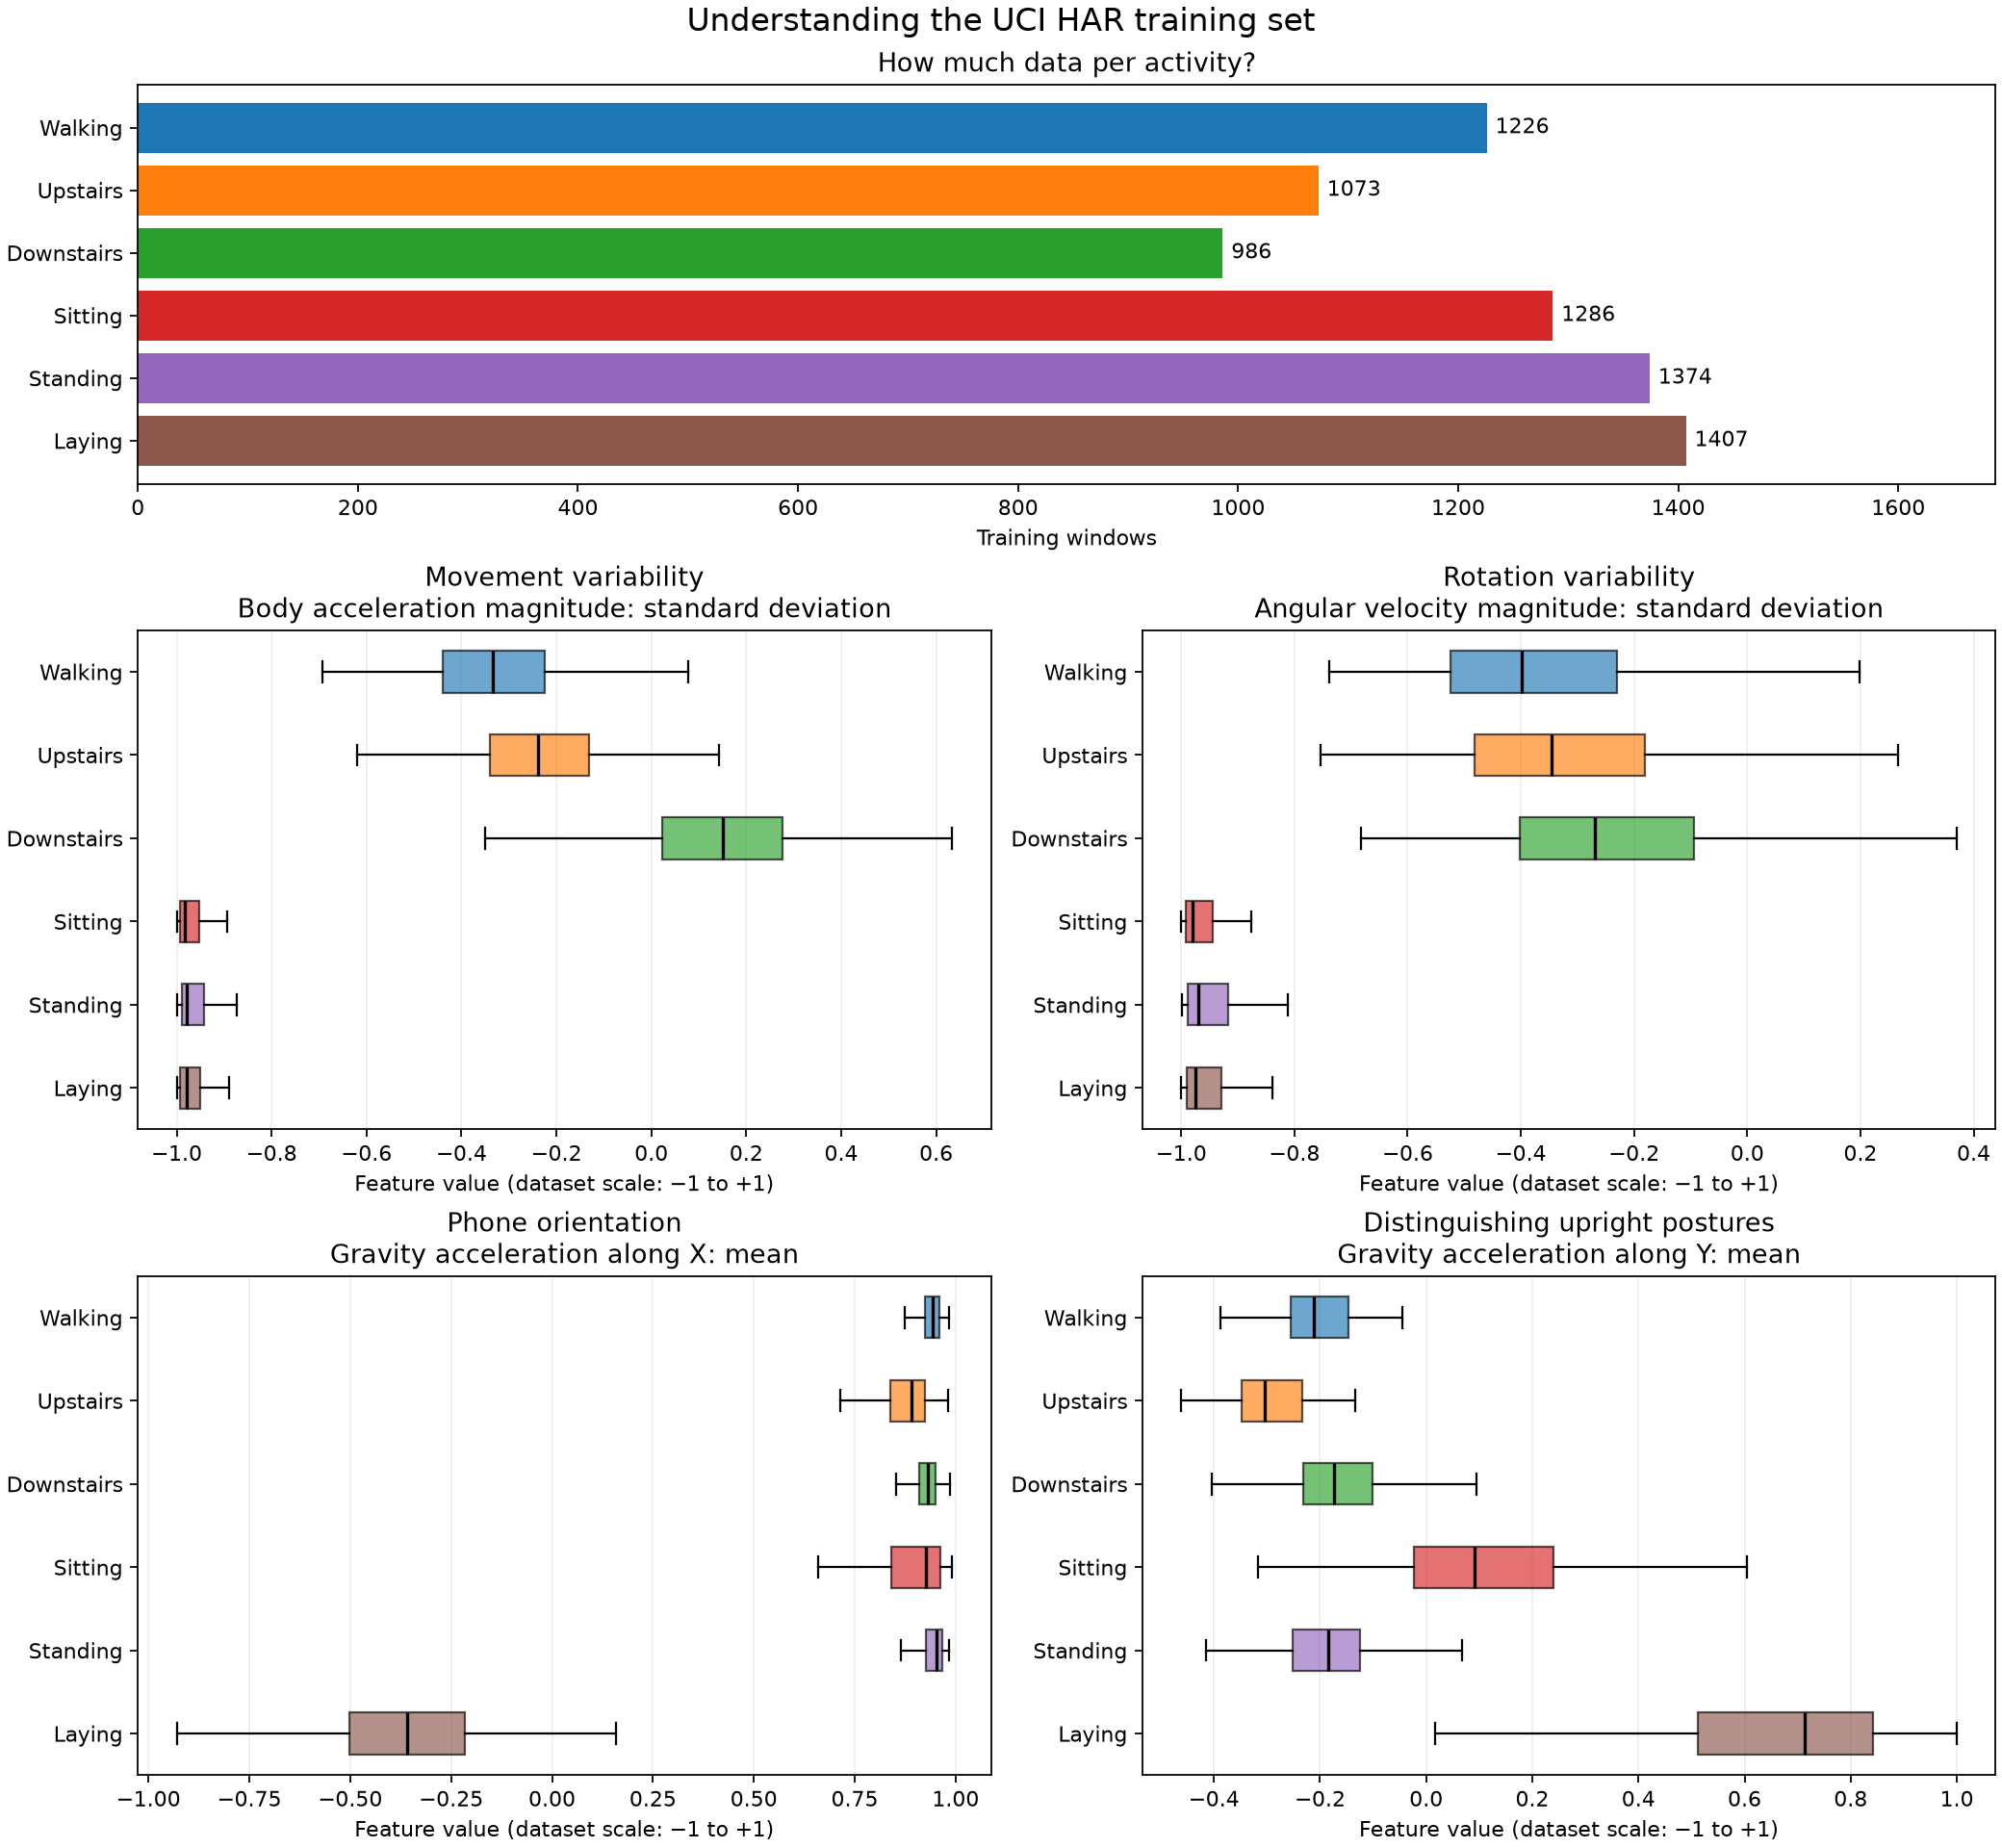

In [3]:
# Explore only the official training split; test files remain unopened.
feature_names = [line.split(maxsplit=1)[1].strip()
                 for line in (DATASET / "features.txt").read_text().splitlines()]
assert len(feature_names) == X.shape[1]
examples = [
    ("tBodyAccMag-std()", "Movement variability", "Body acceleration magnitude: standard deviation"),
    ("tBodyGyroMag-std()", "Rotation variability", "Angular velocity magnitude: standard deviation"),
    ("tGravityAcc-mean()-X", "Phone orientation", "Gravity acceleration along X: mean"),
    ("tGravityAcc-mean()-Y", "Distinguishing upright postures", "Gravity acceleration along Y: mean"),
]
colours = plt.colormaps["tab10"](np.arange(len(CLASSES)))
fig = plt.figure(figsize=(13, 12), layout="constrained")
grid = fig.add_gridspec(3, 2, height_ratios=[0.8, 1, 1])
axes = [fig.add_subplot(grid[0, :])] + [
    fig.add_subplot(grid[row, column]) for row in [1, 2] for column in [0, 1]
]
counts = [int(np.sum(y == label)) for label in CLASSES]
bars = axes[0].barh(ACTIVITIES, counts, color=colours)
axes[0].bar_label(bars, padding=4)
axes[0].set(xlabel="Training windows", title="How much data per activity?",
            xlim=(0, max(counts) * 1.2))
axes[0].invert_yaxis()
for ax, (feature_name, title, description) in zip(axes[1:], examples):
    column = feature_names.index(feature_name)
    values = [X[y == label, column] for label in CLASSES]
    boxes = ax.boxplot(values, orientation="horizontal", tick_labels=ACTIVITIES,
                       patch_artist=True, showfliers=False,
                       medianprops={"color": "black", "linewidth": 1.5})
    for box, colour in zip(boxes["boxes"], colours):
        box.set_facecolor(colour)
        box.set_alpha(0.65)
    ax.set(xlabel="Feature value (dataset scale: −1 to +1)", title=title + "\n" + description)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.2)
fig.suptitle("Understanding the UCI HAR training set", fontsize=15)
exploration_path = OUT / "dataset-exploration.png"
fig.savefig(exploration_path, dpi=160)
plt.close(fig)
display(Image(filename=str(exploration_path)))

How to read the five panels:

- **Training windows:** each bar counts examples of an activity. All six activities are represented, although the counts differ; lying has the most windows and walking downstairs the fewest.
- **Movement variability:** larger values mean the body-acceleration magnitude changes more within a recording window. Walking activities show much more variation than sitting, standing or lying.
- **Rotation variability:** larger values mean the speed of rotation changes more within a window. The walking activities generally show more variation than the stationary postures. This describes changes in rotation, rather than the phone's fixed angle.
- **Phone orientation:** gravity projected onto the phone's X axis helps distinguish lying from upright postures in these recordings. Sitting and standing overlap, so this feature alone does not reliably separate them.
- **Distinguishing upright postures:** gravity along Y adds a second view of phone orientation. In these training recordings, Sitting has a higher median and a different central range than Standing, helping distinguish two activities that overlap strongly along X. The full distributions still overlap, so this is useful information rather than a perfect decision rule.
- **Axis scale:** these are the dataset's normalised values between −1 and +1, before our `StandardScaler`. For a variability feature, a value near −1 means low variability; it does not mean negative physical variability.
- **What we learn:** different features describe different aspects of an activity, and their distributions can overlap. This helps explain why the classifier combines measurements. These examples illustrate the training data; they do not select features or measure model accuracy.

Other aspects included in the 561 features, but not plotted here, include:

- **Movement rhythms:** how quickly movements repeat and how strongly different rhythms appear.
- **Changes in acceleration:** how abruptly acceleration changes during a window.
- **Signal energy:** a summary based on squared signal values, describing their overall strength.
- **Signal irregularity:** whether the readings have a more regular or less predictable pattern.
- **Coordination between axes:** how readings along different movement directions vary together.
- **Other directions and angles:** equivalent summaries along other axes and angles between signal vectors and gravity.

## 3. Model and parameter selection

We use `StandardScaler` followed by `LinearSVC`, with all 561 features. The scaler centres and rescales each feature using statistics learned from the training data. The SVM assigns a score to each activity and selects the highest one. Its weighted sums are suitable for implementation in C.


We keep the supplied features as a straightforward baseline and use regularisation to control the linear classifier, limiting the parameter search here to `C`. The exported six-class model contains 3,372 float32 weights and biases; this excludes feature extraction and other firmware memory. We do not claim that all features are necessary or that this is the smallest possible model.

`C` controls the penalty for training margin violations relative to the weight penalty: smaller values give stronger regularisation, while larger values put more emphasis on fitting the training data. Stronger regularisation discourages large weights and can help limit overfitting.

The next cell compares `C=0.1`, `1` and `10` with three-fold `GroupKFold` on the official training set. Every candidate uses the same subject groups, and a new scaler is fitted only on the training rows of each fold. We select the value with the highest mean validation macro-F1; a tie favours the smaller value. The test set does not participate in this selection. The result identifies the best of these three candidates under this protocol, not a global optimum.

In [4]:
C_VALUES = [0.1, 1.0, 10.0]
selection_splits = list(GroupKFold(n_splits=3).split(X, y, subjects))
selection_protocol = {
    "C_values": C_VALUES, "folds": 3, "grouping": "subject",
    "metric": "mean fold macro-F1", "tie_break": "smaller C",
    "features": 561, "dual": "auto", "max_iter": 5000, "random_state": 42,
    "official_test_used": False,
}
(OUT / "selection-protocol.json").write_text(json.dumps(selection_protocol, indent=2) + "\n")
selection_rows = []
for c_value in C_VALUES:
    for fold, (fit_indices, valid_indices) in enumerate(selection_splits, 1):
        fit_subjects = sorted(map(int, np.unique(subjects[fit_indices])))
        valid_subjects = sorted(map(int, np.unique(subjects[valid_indices])))
        assert not set(fit_subjects) & set(valid_subjects)
        model = make_pipeline(
            StandardScaler(),
            LinearSVC(C=c_value, dual="auto", max_iter=5000, random_state=42),
        )
        model.fit(X[fit_indices], y[fit_indices])
        assert int(model[0].n_samples_seen_) == len(fit_indices)
        predictions = model.predict(X[valid_indices])
        selection_rows.append({
            "C": c_value, "fold": fold, "training_subjects": fit_subjects,
            "validation_subjects": valid_subjects, "subject_overlap": 0,
            "macro_f1": float(f1_score(y[valid_indices], predictions, average="macro", zero_division=0)),
        })
        print(f"C={c_value:g}: completed selection fold {fold}/3", flush=True)
selection_summary = [
    {"C": c_value,
     "mean_macro_f1": float(np.mean([r["macro_f1"] for r in selection_rows if r["C"] == c_value]))}
    for c_value in C_VALUES
]
selected_C = max(selection_summary, key=lambda r: (r["mean_macro_f1"], -r["C"]))["C"]
selection = {"protocol": selection_protocol, "folds": selection_rows,
             "summary": selection_summary, "selected_C": selected_C}
(OUT / "c-selection.json").write_text(json.dumps(selection, indent=2) + "\n")
rows = ["| C | Fold 1 macro-F1 | Fold 2 macro-F1 | Fold 3 macro-F1 | Mean macro-F1 | Selected |",
        "|---|---:|---:|---:|---:|---|"]
for result in selection_summary:
    scores = [r["macro_f1"] for r in selection_rows if r["C"] == result["C"]]
    rows.append(f"| {result['C']:g} | " + " | ".join(f"{score:.2%}" for score in scores)
                + f" | {result['mean_macro_f1']:.2%} | {'Yes' if result['C'] == selected_C else ''} |")
display(Markdown("\n".join(rows)))
print(f"Selected C: {selected_C:g}")

C=0.1: completed selection fold 1/3


C=0.1: completed selection fold 2/3


C=0.1: completed selection fold 3/3


C=1: completed selection fold 1/3


C=1: completed selection fold 2/3


C=1: completed selection fold 3/3


C=10: completed selection fold 1/3


C=10: completed selection fold 2/3


C=10: completed selection fold 3/3


| C | Fold 1 macro-F1 | Fold 2 macro-F1 | Fold 3 macro-F1 | Mean macro-F1 | Selected |
|---|---:|---:|---:|---:|---|
| 0.1 | 95.59% | 87.18% | 91.93% | 91.56% | Yes |
| 1 | 94.26% | 86.50% | 91.43% | 90.73% |  |
| 10 | 93.35% | 86.20% | 90.15% | 89.90% |  |

Selected C: 0.1


### Subject-grouped validation of the selected configuration

We now evaluate the selected configuration with five-fold `GroupKFold`, grouping windows by person. A random split of individual windows could put similar recordings from the same person in both training and validation. Keeping subjects separate avoids this overlap.

With five folds, each iteration holds out four or five people and trains on the remaining 16 or 17. We fit a new scaler and classifier within each fold, using only its training rows. Every window receives one out-of-fold (OOF) prediction from a model that has not fitted that person's data.

In [5]:
protocol = dict(
    features=561, C=selected_C, dual="auto", max_iter=5000,
    random_state=42, folds=5, grouping="subject", feature_selection=False,
    hyperparameter_search=True, selection_folds=3, C_values=C_VALUES,
    rejection_threshold=False,
)
(OUT / "protocol.json").write_text(json.dumps(protocol, indent=2) + "\n")
pipeline = make_pipeline(
    StandardScaler(),
    LinearSVC(
        C=protocol["C"],
        dual=protocol["dual"],
        max_iter=protocol["max_iter"],
        random_state=protocol["random_state"],
    ),
)
print("Selected configuration:", protocol)

Selected configuration: {'features': 561, 'C': 0.1, 'dual': 'auto', 'max_iter': 5000, 'random_state': 42, 'folds': 5, 'grouping': 'subject', 'feature_selection': False, 'hyperparameter_search': True, 'selection_folds': 3, 'C_values': [0.1, 1.0, 10.0], 'rejection_threshold': False}


In [6]:
oof_predictions = np.zeros_like(y)
coverage = np.zeros(len(y), dtype=int)
fold_rows = []
splitter = GroupKFold(n_splits=protocol["folds"])
for fold, (fit_indices, valid_indices) in enumerate(splitter.split(X, y, subjects), 1):
    fit_subjects = sorted(map(int, np.unique(subjects[fit_indices])))
    valid_subjects = sorted(map(int, np.unique(subjects[valid_indices])))
    assert not set(fit_subjects) & set(valid_subjects)

    # A new pipeline prevents fitted scaling parameters leaking across folds
    fitted_fold = clone(pipeline).fit(X[fit_indices], y[fit_indices])
    predictions = fitted_fold.predict(X[valid_indices])
    oof_predictions[valid_indices] = predictions
    coverage[valid_indices] += 1
    fold_rows.append({
        "fold": fold,
        "training_subjects": fit_subjects,
        "validation_subjects": valid_subjects,
        "subject_overlap": 0,
        "training_rows": len(fit_indices),
        "validation_rows": len(valid_indices),
        "scaler_samples_seen": int(fitted_fold[0].n_samples_seen_),
        "accuracy": float(accuracy_score(y[valid_indices], predictions)),
        "macro_f1": float(f1_score(y[valid_indices], predictions, average="macro", zero_division=0)),
    })
    assert fold_rows[-1]["scaler_samples_seen"] == len(fit_indices)
    print(f"Completed fold {fold}/{protocol['folds']}")
assert np.all(coverage == 1)

Completed fold 1/5


Completed fold 2/5


Completed fold 3/5


Completed fold 4/5


Completed fold 5/5


## 4. Validation results

Accuracy is the proportion of correctly classified windows. Although this task has six classes, we calculate precision, recall and F1 separately for each activity, treating that activity as positive and all five other activities as negative (one-versus-rest). This describes how we calculate the metrics, rather than an additional model-training step.

For an activity $k$:

- **True positives ($TP_k$):** windows whose true and predicted activity are both $k$.
- **False positives ($FP_k$):** windows from another activity predicted as $k$.
- **False negatives ($FN_k$):** windows of activity $k$ predicted as another activity.
- **Precision:** among windows predicted as $k$, the fraction that really belong to $k$.
- **Recall:** among windows that really belong to $k$, the fraction recognised as $k$.

$$
\mathrm{Precision}_k = \frac{TP_k}{TP_k + FP_k},
\qquad
\mathrm{Recall}_k = \frac{TP_k}{TP_k + FN_k}.
$$

For example, when evaluating Walking, another activity predicted as Walking is a false positive, while Walking predicted as another activity is a false negative. We repeat this calculation for each of the six activities.

F1 is the harmonic mean of precision and recall for each activity:

$$
F1_k = \frac{2\,\mathrm{Precision}_k\,\mathrm{Recall}_k}
{\mathrm{Precision}_k + \mathrm{Recall}_k}
$$

**Macro-F1** is the arithmetic mean of the six per-activity F1 scores:

$$
\mathrm{Macro\text{-}F1} = \frac{1}{6}\sum_{k=1}^{6} F1_k.
$$

- **Why macro averaging:** every activity receives equal weight, regardless of how many windows it has. Strong results on a more frequent activity therefore do not receive extra weight in the average.
- **What it averages:** the six F1 scores, rather than computing F1 from the average precision and average recall.
- **Zero denominators:** the metric calls below use `zero_division=0`, reporting zero when a metric is undefined because its denominator is zero.

We summarise the validation predictions in two ways:

- **Mean fold score:** calculate macro-F1 separately for each fold, then average the five scores. Each fold receives equal weight, regardless of its number of windows.
- **Pooled OOF score:** combine all out-of-fold predictions, then calculate macro-F1 once from the combined per-class counts. This can differ from the mean fold score because averaging F1 scores is not the same as calculating F1 from combined counts, even when folds have equal sizes.

The standard deviation of the fold scores describes variation between subject groups; it is not a confidence interval.


In [7]:
oof_report = classification_report(y, oof_predictions, output_dict=True, zero_division=0)
oof_matrix = confusion_matrix(y, oof_predictions, labels=CLASSES)
validation = {
    "scope": "internal grouped validation after training-only C selection; not nested cross-validation",
    "official_test_used": False,
    "model_selection_on_test": False,
    "recipe": protocol,
    "selection": selection,
    "folds": fold_rows,
    "rows": len(y),
    "subjects": sorted(map(int, np.unique(subjects))),
    "oof_accuracy": float(accuracy_score(y, oof_predictions)),
    "oof_macro_f1": float(f1_score(y, oof_predictions, average="macro", zero_division=0)),
    "fold_macro_f1_mean": float(np.mean([row["macro_f1"] for row in fold_rows])),
    "fold_macro_f1_std": float(np.std([row["macro_f1"] for row in fold_rows], ddof=1)),
    "confusion_matrix": oof_matrix.tolist(),
    "classification_report": oof_report,
    "all_rows_predicted_once": True,
    "limitation": "C selection and OOF diagnostics reuse training subjects; these diagnostics do not independently evaluate selection",
    "numpy": np.__version__,
    "sklearn": sklearn.__version__,
    "files_sha256": {str(p.relative_to(DATASET)): hashlib.sha256(p.read_bytes()).hexdigest()
                     for p in training_paths},
    "firmware_replaced": False,
}
np.savetxt(
    OUT / "oof_predictions.csv",
    np.column_stack((subjects, y, oof_predictions)),
    fmt="%d",
    delimiter=",",
    header="subject,true,predicted",
    comments="",
)
rows = ["| Fold | Fit subjects | Held-out subjects | Accuracy | Macro-F1 |",
        "|---|---:|---:|---:|---:|"]
for row in fold_rows:
    rows.append(f"| {row['fold']} | {len(row['training_subjects'])} | "
                f"{len(row['validation_subjects'])} | {row['accuracy']:.2%} | {row['macro_f1']:.2%} |")
display(Markdown("\n".join(rows)))
print(f"Aggregate OOF accuracy: {validation['oof_accuracy']:.2%}")
print(f"Aggregate OOF macro-F1: {validation['oof_macro_f1']:.2%}")
print(f"Mean fold macro-F1: {validation['fold_macro_f1_mean']:.2%}")
print(f"Fold standard deviation: {100 * validation['fold_macro_f1_std']:.2f} percentage points")

| Fold | Fit subjects | Held-out subjects | Accuracy | Macro-F1 |
|---|---:|---:|---:|---:|
| 1 | 17 | 4 | 90.07% | 89.09% |
| 2 | 17 | 4 | 89.93% | 89.98% |
| 3 | 17 | 4 | 98.66% | 98.68% |
| 4 | 17 | 4 | 95.67% | 95.67% |
| 5 | 16 | 5 | 94.42% | 94.84% |

Aggregate OOF accuracy: 93.77%
Aggregate OOF macro-F1: 93.66%
Mean fold macro-F1: 93.65%
Fold standard deviation: 4.03 percentage points


| Activity | Precision | Recall | F1 | Windows |
|---|---:|---:|---:|---:|
| Walking | 96.27% | 92.58% | 94.39% | 1226 |
| Upstairs | 89.24% | 93.57% | 91.36% | 1073 |
| Downstairs | 95.68% | 92.19% | 93.90% | 986 |
| Sitting | 88.81% | 92.61% | 90.67% | 1286 |
| Standing | 92.83% | 91.41% | 92.12% | 1374 |
| Laying | 99.64% | 99.43% | 99.54% | 1407 |

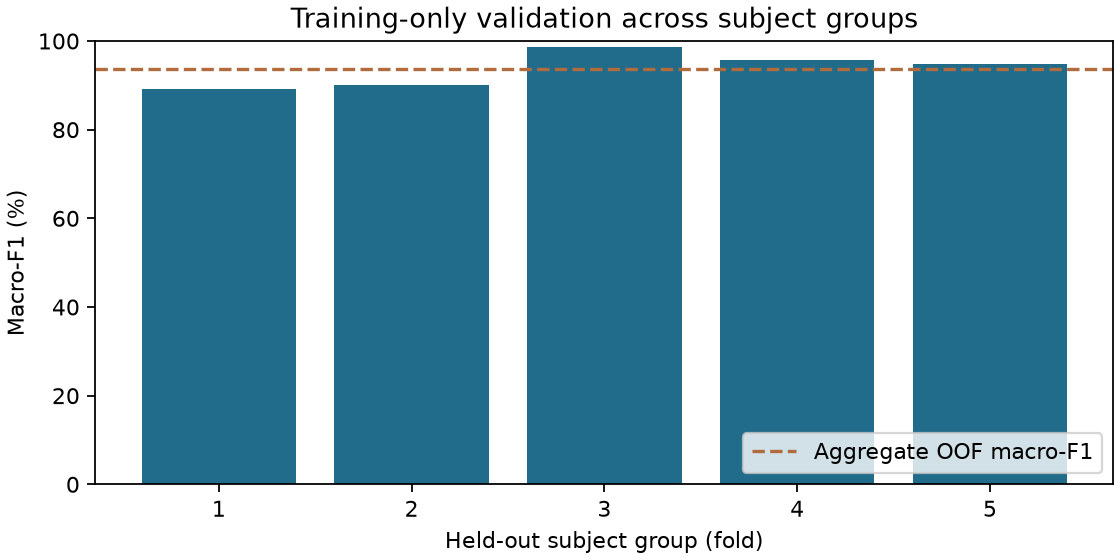

In [8]:
rows = ["| Activity | Precision | Recall | F1 | Windows |", "|---|---:|---:|---:|---:|"]
for label, name in zip(CLASSES, ACTIVITIES):
    score = oof_report[str(label)]
    rows.append(f"| {name} | {score['precision']:.2%} | {score['recall']:.2%} | "
                f"{score['f1-score']:.2%} | {int(score['support'])} |")
display(Markdown("\n".join(rows)))

fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.bar([row["fold"] for row in fold_rows],
       [100 * row["macro_f1"] for row in fold_rows], color="#216b8b")
ax.axhline(100 * validation["oof_macro_f1"], color="#b16b3c", linestyle="--",
           label="Aggregate OOF macro-F1")
ax.set(xlabel="Held-out subject group (fold)", ylabel="Macro-F1 (%)", ylim=(0, 100),
       xticks=range(1, 6), title="Training-only validation across subject groups")
ax.legend(loc="lower right")
fig.savefig(OUT / "oof-folds.png", dpi=160)
display(Image(filename=str(OUT / "oof-folds.png")))
plt.close(fig)

Observations on the fold scores:

- Each bar is macro-F1 on the people held out in one fold. The dashed line is the pooled OOF macro-F1 (93.66%), rather than the average bar height.
- Differences between groups: scores range from 89.09% in fold 1 to 98.68% in fold 3. Folds 1 and 2 are more challenging for their respective fitted models than the other groups; performance is not uniform across held-out people.
- The mean fold macro-F1 is 93.65%, close to the pooled OOF score of 93.66%. 

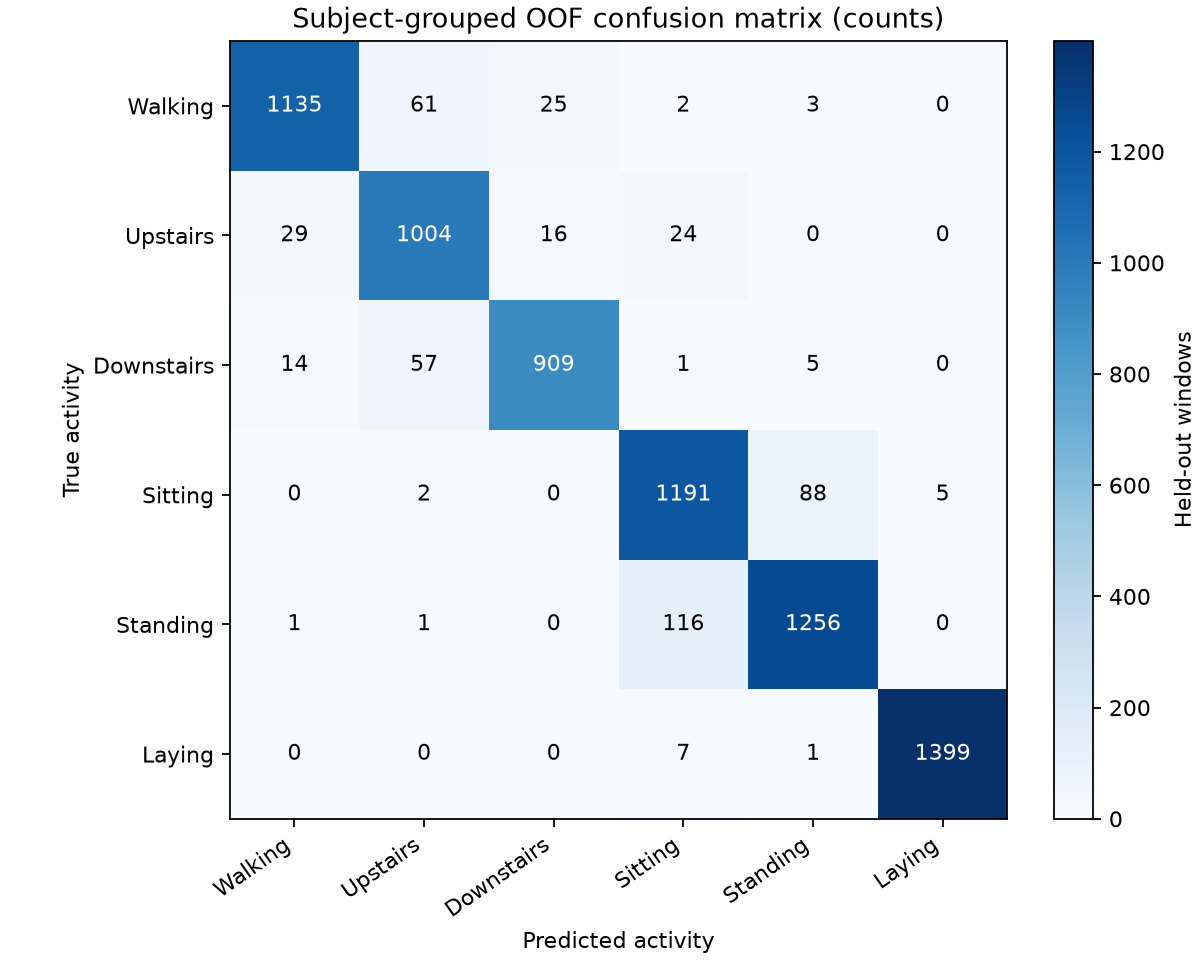

Largest off-diagonal count: Standing -> Sitting 116


In [9]:
fig, ax = plt.subplots(figsize=(7.5, 6), layout="constrained")
image = ax.imshow(oof_matrix, cmap="Blues")
fig.colorbar(image, ax=ax, label="Held-out windows")
ax.set(xticks=range(6), yticks=range(6), xticklabels=ACTIVITIES, yticklabels=ACTIVITIES,
       xlabel="Predicted activity", ylabel="True activity",
       title="Subject-grouped OOF confusion matrix (counts)")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
for true_class in range(6):
    for predicted_class in range(6):
        value = oof_matrix[true_class, predicted_class]
        color = "white" if value > oof_matrix.max() / 2 else "black"
        ax.text(predicted_class, true_class, str(value), ha="center", va="center", color=color)
fig.savefig(OUT / "oof-confusion-matrix.png", dpi=160)
display(Image(filename=str(OUT / "oof-confusion-matrix.png")))
plt.close(fig)

# Summarize the largest observed confusion without selecting new parameters
errors_by_pair = oof_matrix.copy()
np.fill_diagonal(errors_by_pair, 0)
true_class, predicted_class = np.unravel_index(np.argmax(errors_by_pair), errors_by_pair.shape)
print("Largest off-diagonal count:", ACTIVITIES[true_class], "->",
      ACTIVITIES[predicted_class], int(errors_by_pair[true_class, predicted_class]))

Observations on the confusion matrix:

- Rows are the true activities and columns are the predicted activities. Each cell counts held-out windows. The diagonal contains correct predictions; an off-diagonal cell shows a particular error direction.
- **Main confusion:** 116 Standing windows are predicted as Sitting, and 88 Sitting windows as Standing. These are the two largest individual error counts; distinguishing the two upright postures remains a weakness.
- **Walking activities also overlap:** 61 Walking windows and 57 Downstairs windows are predicted as Upstairs. Thus, recognising movement does not always mean recognising the correct walking activity.
- **Lying is recognised particularly well:** 1,399 of its 1,407 windows are correctly classified, with eight errors. Its per-class F1 is 99.54%, the highest of the six activities in these OOF results.
- **Counts and proportions:** activities have different numbers of windows, so compare the matrix with the per-activity precision, recall and F1 table above. A darker diagonal cell alone does not establish better performance.

## 5. Final training and scaling

We now fit a new pipeline on all 21 training subjects, using the same settings. The five fold models are not combined. The official test set remains outside training.

For the C implementation, we incorporate the scaler into the classifier coefficients: we divide each weight by its feature's scale and adjust the bias using the feature means. The device can then calculate each activity score as a weighted sum plus the bias, without a separate scaling step. It receives the published UCI features in their original order, rather than raw sensor readings.

The next cell checks that the adjusted coefficients reproduce the pipeline's training predictions.

In [10]:
final_pipeline = clone(pipeline).fit(X, y)
scaler, svm = final_pipeline.steps[0][1], final_pipeline.steps[1][1]
weights = svm.coef_ / scaler.scale_
bias = svm.intercept_ - weights @ scaler.mean_
candidate = {
    "name": "svm561",
    "classes": svm.classes_.tolist(),
    "indices": list(range(561)),
    "weights": weights.tolist(),
    "bias": bias.tolist(),
}
candidate_path = OUT / "svm561.json"
candidate_path.write_text(json.dumps(candidate))
validation["candidate_sha256"] = hashlib.sha256(candidate_path.read_bytes()).hexdigest()
(OUT / "validation.json").write_text(json.dumps(validation, indent=2) + "\n")

# Check the algebraic transformation on training inputs without using test data
folded_predictions = np.asarray(candidate["classes"])[(X @ weights.T + bias).argmax(axis=1)]
assert np.array_equal(folded_predictions, final_pipeline.predict(X))
print("Candidate saved:", candidate_path)
print("Fitted scaler rows:", scaler.n_samples_seen_)
print("Folded-coefficient predictions match the fitted pipeline on training rows")

Candidate saved: /Users/martina/ActivityLink-IoT-2026/runtime/notebook-standalone-review/execution-results-exploration/svm561.json
Fitted scaler rows: 7352.0
Folded-coefficient predictions match the fitted pipeline on training rows


## 6. C export

We export the model trained above as float32 coefficient arrays and a C prediction function. The header is saved in the output directory. This notebook does not overwrite firmware files or flash devices.

In [11]:
def export_header(model):
    assert model["classes"] == [1, 2, 3, 4, 5, 6]
    assert model["indices"] == list(range(561))
    lines = ["/* Input: all 561 UCI HAR features in original dataset order */",
             "#include <stddef.h>"]
    for name, array in [
        ("weights", np.asarray(model["weights"], dtype=np.float32).ravel()),
        ("bias", np.asarray(model["bias"], dtype=np.float32)),
    ]:
        lines.append(
            f"static const float har_{name}[{array.size}]={{"
            + ",".join(f"{float(value):.9e}f" for value in array)
            + "};"
        )
    lines.append(
        "int har_predict(const float x[561]) {\n"
        "  int best = 0;\n"
        "  float top = 0;\n"
        "  for (int c = 0; c < 6; c++) {\n"
        "    float s = har_bias[c];\n"
        "    for (int j = 0; j < 561; j++)\n"
        "      s += har_weights[c * 561 + j] * x[j];\n"
        "    if (c == 0 || s > top) {\n"
        "      top = s;\n"
        "      best = c;\n"
        "    }\n"
        "  }\n"
        "  return best + 1;\n"
        "}"
    )
    return "\n".join(lines)

candidate_header = export_header(candidate)
(OUT / "candidate_predictor.h").write_text(candidate_header)
print("Exported header:", OUT / "candidate_predictor.h")
print("Header SHA-256:", hashlib.sha256(candidate_header.encode()).hexdigest())

Exported header: /Users/martina/ActivityLink-IoT-2026/runtime/notebook-standalone-review/execution-results-exploration/candidate_predictor.h
Header SHA-256: 5b9f0611df1058d1ea9ee6de9b46002585679eec9dd12c3d9101159f17864b80


## 7. Python/C comparison

We compile the exported predictor on the host computer and compare it with the fitted Python pipeline using all official test inputs. Labels are not loaded for this check. Both implementations use the model trained above; 

Zero differences means that the two implementations agree on these inputs, not that every activity is recognised correctly.

In [12]:
if shutil.which("gcc") is None:
    raise RuntimeError("Install a host C compiler before running the equivalence check")

X_test = np.loadtxt(DATASET / "test" / "X_test.txt")
assert X_test.shape == (2947, 561)
assert np.isfinite(X_test).all()
source_path = OUT / "candidate_predictor.c"
source_path.write_text(candidate_header + "\n")
library_path = OUT / ("candidate_predictor.dylib" if sys.platform == "darwin" else "candidate_predictor.so")
link_option = "-dynamiclib" if sys.platform == "darwin" else "-shared"
subprocess.run(["gcc", link_option, "-fPIC", "-O2", "-std=c99", str(source_path),
                "-o", str(library_path)], check=True, capture_output=True, text=True)
c_library = ctypes.CDLL(str(library_path))
c_predict = c_library.har_predict
c_predict.argtypes = [ctypes.POINTER(ctypes.c_float)]
c_predict.restype = ctypes.c_int
c_inputs = np.ascontiguousarray(X_test, dtype=np.float32)
c_predictions = np.array([c_predict(row.ctypes.data_as(ctypes.POINTER(ctypes.c_float)))
                          for row in c_inputs], dtype=int)
python_predictions = final_pipeline.predict(X_test)
folded_test_predictions = np.asarray(candidate["classes"])[(X_test @ weights.T + bias).argmax(axis=1)]
assert np.array_equal(folded_test_predictions, python_predictions)
equivalence = {
    "scope": "host C export versus fitted Python pipeline on official test inputs",
    "samples": len(X_test),
    "mismatches": int(np.count_nonzero(c_predictions != python_predictions)),
    "compiler": subprocess.run(["gcc", "--version"], check=True, capture_output=True, text=True).stdout.splitlines()[0],
    "header_sha256": hashlib.sha256(candidate_header.encode()).hexdigest(),
}
(OUT / "equivalence.json").write_text(json.dumps(equivalence, indent=2) + "\n")
print("Compared input windows:", equivalence["samples"])
print("C/Python prediction mismatches:", equivalence["mismatches"])
print("Compiler:", equivalence["compiler"])

Compared input windows: 2947
C/Python prediction mismatches: 0
Compiler: Apple clang version 14.0.0 (clang-1400.0.29.202)


## 8. Test evaluation

We evaluate the final model on the complete official test windows, after checking that their subjects are separate from the training subjects. The training, `C` selection and OOF validation cells do not read test measurements or labels.

The OOF and test scores measure different cases. Each fold learns from 16 or 17 people, whereas the final model learns from all 21 training subjects.

In [13]:
y_test = np.loadtxt(DATASET / "test" / "y_test.txt", dtype=int)
test_subjects = np.loadtxt(DATASET / "test" / "subject_test.txt", dtype=int)
assert len(X_test) == len(y_test) == len(test_subjects)
assert len(np.unique(test_subjects)) == 9
subject_overlap = set(map(int, subjects)) & set(map(int, test_subjects))
assert not subject_overlap
# Predictions come from the already fitted model; there is no fit or selection here.
test_results = {
    "scope": "official test evaluation of the final model",
    "test_rows": len(y_test), "subjects": sorted(map(int, np.unique(test_subjects))),
    "subject_overlap": len(subject_overlap), "used_for_selection": False,
    "accuracy": float(accuracy_score(y_test, python_predictions)),
    "macro_f1": float(f1_score(y_test, python_predictions, average="macro", zero_division=0)),
    "errors": int(np.count_nonzero(y_test != python_predictions)),
    "classification_report": classification_report(y_test, python_predictions, output_dict=True, zero_division=0),
    "confusion_matrix": confusion_matrix(y_test, python_predictions, labels=CLASSES).tolist(),
}
(OUT / "test-evaluation.json").write_text(json.dumps(test_results, indent=2) + "\n")
rows = ["| Evaluation | Windows | Accuracy | Macro-F1 |",
        "|---|---:|---:|---:|",
        f"| Training-only subject-grouped OOF (after C selection) | {len(y)} | {validation['oof_accuracy']:.2%} | {validation['oof_macro_f1']:.2%} |",
        f"| Official test | {test_results['test_rows']} | {test_results['accuracy']:.2%} | {test_results['macro_f1']:.2%} |"]
display(Markdown("\n".join(rows)))
print("Test errors:", test_results["errors"])
print("Training/test subject overlap:", test_results["subject_overlap"])

| Evaluation | Windows | Accuracy | Macro-F1 |
|---|---:|---:|---:|
| Training-only subject-grouped OOF (after C selection) | 7352 | 93.77% | 93.66% |
| Official test | 2947 | 96.20% | 96.29% |

Test errors: 112
Training/test subject overlap: 0
